# INT315 - Cluster Computing: Project CA 2
## Bank Transaction Fraud Detection & Analytics using PySpark & MLlib

**Course:** INT315 Cluster Computing  
**Project Topic:** Bank Transaction Fraud Detection and Customer Behavior Analytics  
**Platform:** Apache Spark 3.5.9, PySpark, Spark MLlib  
**Dataset:** Bank_Transaction_Fraud_Detection.csv (200,000 records, 24 features)

---

### Objectives & Syllabus Coverage:
1. **PySpark Setup & SparkSession:** In-session environment isolation (JDK 8 + Spark 3.5.9).
2. **Data Cleaning & Spark SQL:** Schema validation, missing value audit, and feature extraction (`Transaction_Hour`).
3. **Exploratory Data Analysis & Statistics:** Class distribution and **Correlation Heat Map**.
4. **Unsupervised Learning:** **K-Means Clustering** with `StandardScaler` and **Silhouette Score** evaluation.
5. **Supervised Regression:** **Linear Regression** to predict `Transaction_Amount`, evaluated using **$R^2$**, **RMSE**, and **MAE**, with an **Actual vs. Predicted** plot.
6. **Supervised Classification:** Fraud Detection using:
   - **Logistic Regression**
   - **Decision Tree Classifier**
   - **Support Vector Machine (LinearSVC)**
   - **Naive Bayes Classifier**
7. **Performance Matrix:** Multi-model comparison and **Confusion Matrix** visualization.


### Step 1: Environment Setup & SparkSession Creation
We configure Java 8 and Spark 3.5.9 dynamically within this session so that the global system setup (e.g., Java 24) is not altered.


In [1]:
import os
import sys

# Configure JDK 8 and Spark 3.5.9 paths locally for this project session
os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk1.8.0_501"
os.environ["SPARK_HOME"] = r"C:\Spark"
os.environ["HADOOP_HOME"] = r"C:\Spark"
os.environ["PATH"] = os.path.join(os.environ["JAVA_HOME"], "bin") + ";" + \
                     os.path.join(os.environ["SPARK_HOME"], "bin") + ";" + \
                     os.environ.get("PATH", "")

# Import standard data analysis and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import PySpark components
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, hour, when, count

# Initialize local SparkSession (utilizing all available CPU cores)
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("INT315_Bank_Transaction_Fraud_Detection") \
    .config("spark.driver.memory", "2g") \
    .getOrCreate()

# Reduce log verbosity to display only errors
spark.sparkContext.setLogLevel("ERROR")

print("PySpark Session successfully created!")
print("Spark Version :", spark.version)
print("Application ID:", spark.sparkContext.applicationId)


PySpark Session successfully created!
Spark Version : 3.5.9
Application ID: local-1792786442152


### Step 2: Data Loading and Schema Inspection
We load the 200,000-row CSV file into a distributed PySpark DataFrame with automatic schema inference.


In [2]:
# Path to the bank transaction dataset
csv_file_path = "Bank_Transaction_Fraud_Detection.csv"

# Read dataset with header enabled and schema inferred
df = spark.read.csv(csv_file_path, header=True, inferSchema=True)

# Dataset summary statistics
total_rows = df.count()
total_columns = len(df.columns)

print(f"Total Rows in Dataset    : {total_rows}")
print(f"Total Columns in Dataset : {total_columns}")

# Print DataFrame Schema
df.printSchema()

# Preview the first 5 records
df.show(5, truncate=True)


Total Rows in Dataset    : 200000
Total Columns in Dataset : 24
root
 |-- Customer_ID: string (nullable = true)
 |-- Customer_Name: string (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- State: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Bank_Branch: string (nullable = true)
 |-- Account_Type: string (nullable = true)
 |-- Transaction_ID: string (nullable = true)
 |-- Transaction_Date: string (nullable = true)
 |-- Transaction_Time: timestamp (nullable = true)
 |-- Transaction_Amount: double (nullable = true)
 |-- Merchant_ID: string (nullable = true)
 |-- Transaction_Type: string (nullable = true)
 |-- Merchant_Category: string (nullable = true)
 |-- Account_Balance: double (nullable = true)
 |-- Transaction_Device: string (nullable = true)
 |-- Transaction_Location: string (nullable = true)
 |-- Device_Type: string (nullable = true)
 |-- Is_Fraud: integer (nullable = true)
 |-- Transaction_Currency: string (nullab

### Step 3: Data Cleaning and Feature Engineering
In this step, we:
1. Extract the numerical hour of the day (`Transaction_Hour`) from `Transaction_Time`.
2. Remove uninformative identifier columns (UUIDs, names, masked phone/emails) to prevent overfitting and memory bloat.
3. Cast numerical features to double precision as expected by Spark MLlib.


In [3]:
# Extract transaction hour (0 to 23) from the timestamp column
df_clean = df.withColumn("Transaction_Hour", hour(col("Transaction_Time")).cast("double"))

# Define columns to keep for machine learning
categorical_cols = ["Gender", "Account_Type", "Transaction_Type", "Merchant_Category", "Device_Type"]
numerical_cols = ["Age", "Account_Balance", "Transaction_Hour"]

# Ensure all numerical columns are cast to double precision
for num_col in numerical_cols + ["Transaction_Amount", "Is_Fraud"]:
    df_clean = df_clean.withColumn(num_col, col(num_col).cast("double"))

# Select modeling features and drop any missing or null records
df_model = df_clean.select(*(categorical_cols + numerical_cols + ["Transaction_Amount", "Is_Fraud"])).dropna()

valid_records = df_model.count()
print(f"Records successfully prepared for modeling: {valid_records}")
df_model.show(5)


Records successfully prepared for modeling: 200000
+------+------------+----------------+-----------------+-----------+----+---------------+----------------+------------------+--------+
|Gender|Account_Type|Transaction_Type|Merchant_Category|Device_Type| Age|Account_Balance|Transaction_Hour|Transaction_Amount|Is_Fraud|
+------+------------+----------------+-----------------+-----------+----+---------------+----------------+------------------+--------+
|  Male|     Savings|        Transfer|       Restaurant|        POS|60.0|       74557.27|            16.0|          32415.45|     0.0|
|Female|    Business|    Bill Payment|       Restaurant|    Desktop|51.0|       74622.66|            17.0|           43622.6|     0.0|
|  Male|     Savings|    Bill Payment|        Groceries|    Desktop|20.0|       66817.99|             3.0|          63062.56|     0.0|
|Female|    Business|           Debit|    Entertainment|     Mobile|57.0|       58177.08|            12.0|          14000.72|     0.0|
|Fem

### Step 4: Exploratory Data Analysis & Correlation Heatmap
We examine the distribution between legitimate transactions and fraudulent transactions, followed by a Pearson Correlation Heatmap for numerical features.


--- Class Distribution: Legitimate vs Fraudulent Transactions ---
+--------+------+--------------+
|Is_Fraud| count|Percentage (%)|
+--------+------+--------------+
|     0.0|189912|         94.96|
|     1.0| 10088|          5.04|
+--------+------+--------------+



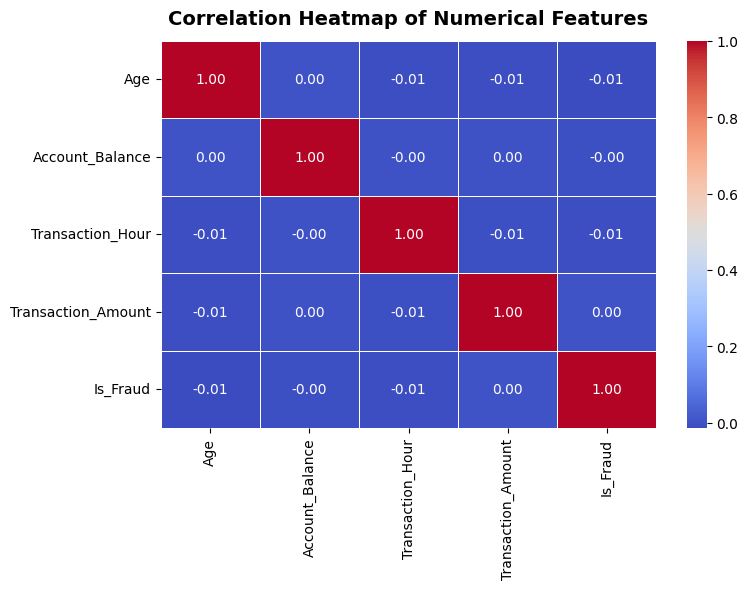

In [4]:
# Target Class Balance (Is_Fraud: 0 vs 1)
print("--- Class Distribution: Legitimate vs Fraudulent Transactions ---")
class_dist = df_model.groupBy("Is_Fraud") \
                     .count() \
                     .withColumn("Percentage (%)", (col("count") / valid_records * 100).cast("decimal(5,2)"))
class_dist.show()

# Select numerical features for correlation matrix calculation
numeric_features = ["Age", "Account_Balance", "Transaction_Hour", "Transaction_Amount", "Is_Fraud"]

# Convert a representative sample to a Pandas DataFrame for plotting
sample_pd = df_model.select(*numeric_features).sample(fraction=0.1, seed=42).toPandas()

# Calculate Pearson correlation matrix
correlation_matrix = sample_pd.corr()

# Plot the Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar=True)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


### Step 5: Unsupervised Learning - K-Means Clustering
We perform customer transaction profiling using K-Means clustering.
- **Feature Standardization:** Because transaction amounts and account balances are much larger than age or hours, we scale them using `StandardScaler` (Mean = 0, Std = 1).
- **Evaluation Metric:** **Silhouette Score** calculated via Spark's `ClusteringEvaluator`.


In [5]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml import Pipeline

# 1. Select transaction features for clustering
kmeans_features = ["Age", "Transaction_Amount", "Account_Balance", "Transaction_Hour"]

# 2. Assemble features into a vector
km_assembler = VectorAssembler(inputCols=kmeans_features, outputCol="km_raw_features")

# 3. Standardize features to have zero mean and unit variance
km_scaler = StandardScaler(inputCol="km_raw_features", outputCol="km_scaled_features", withStd=True, withMean=True)

# 4. Define K-Means with 3 clusters
kmeans = KMeans(featuresCol="km_scaled_features", k=3, seed=42)

# 5. Build and execute the clustering pipeline
km_pipeline = Pipeline(stages=[km_assembler, km_scaler, kmeans])
km_model = km_pipeline.fit(df_model)

# 6. Transform DataFrame to assign cluster IDs
km_predictions = km_model.transform(df_model)

# 7. Evaluate clustering performance with Silhouette Score
km_evaluator = ClusteringEvaluator(featuresCol="km_scaled_features", metricName="silhouette", distanceMeasure="squaredEuclidean")
silhouette = km_evaluator.evaluate(km_predictions)

print("="*50)
print(f"K-Means Clustering Evaluation (k = 3)")
print(f"Silhouette Score : {silhouette:.4f}")
print("="*50)

# Display sample cluster assignments
km_predictions.select("Age", "Transaction_Amount", "Account_Balance", "Transaction_Hour", "prediction").show(5)


K-Means Clustering Evaluation (k = 3)
Silhouette Score : 0.2822
+----+------------------+---------------+----------------+----------+
| Age|Transaction_Amount|Account_Balance|Transaction_Hour|prediction|
+----+------------------+---------------+----------------+----------+
|60.0|          32415.45|       74557.27|            16.0|         1|
|51.0|           43622.6|       74622.66|            17.0|         2|
|20.0|          63062.56|       66817.99|             3.0|         0|
|57.0|          14000.72|       58177.08|            12.0|         1|
|43.0|          18335.16|       16108.56|            18.0|         1|
+----+------------------+---------------+----------------+----------+
only showing top 5 rows



### Step 6: Feature Encoding and Train/Test Split
Categorical columns (`Gender`, `Account_Type`, `Transaction_Type`, `Merchant_Category`, `Device_Type`) are converted to numerical indices using `StringIndexer` and then one-hot encoded using `OneHotEncoder`.
The dataset is then partitioned into **80% Training** and **20% Testing** subsets.


In [6]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder

# Create StringIndexer and OneHotEncoder stages for each categorical column
indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in categorical_cols]
encoders = [OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_vec") for c in categorical_cols]
encoded_cols = [f"{c}_vec" for c in categorical_cols]

# Split dataset into 80% Train and 20% Test sets
train_data, test_data = df_model.randomSplit([0.8, 0.2], seed=42)

print(f"Training Dataset Count : {train_data.count()}")
print(f"Testing Dataset Count  : {test_data.count()}")


Training Dataset Count : 160310
Testing Dataset Count  : 39690


### Step 7: Supervised Regression - Linear Regression
We train a **Linear Regression** model to predict `Transaction_Amount` using customer demographic, temporal, and account characteristics.
- **Evaluation Metrics:** **$R^2$** (Coefficient of Determination), **RMSE** (Root Mean Squared Error), and **MAE** (Mean Absolute Error).
- **Visualization:** Scatter plot of **Actual vs. Predicted** values.


Linear Regression Model Evaluation Results
R² Score (Coefficient of Determination) : -0.0003
Root Mean Squared Error (RMSE)          : ₹28,485.82
Mean Absolute Error (MAE)               : ₹24,659.82


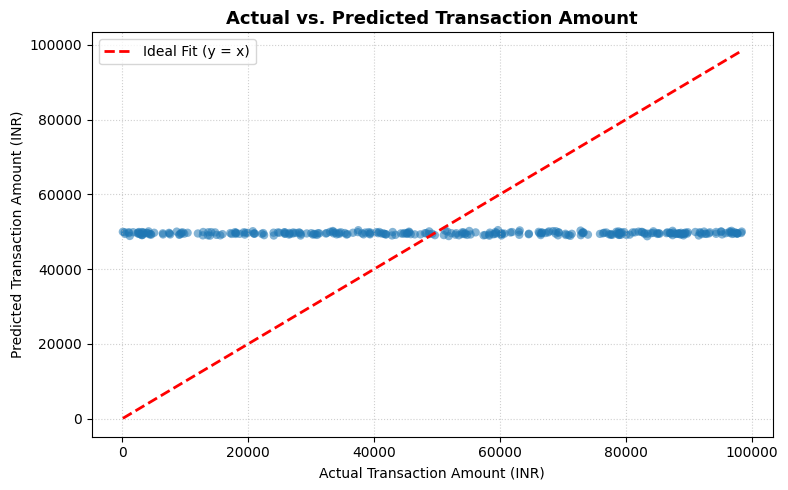

In [7]:
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# Assemble input features for regression (encoded categoricals + numericals)
reg_feature_cols = encoded_cols + numerical_cols
reg_assembler = VectorAssembler(inputCols=reg_feature_cols, outputCol="reg_features")

# Initialize Linear Regression model
lr = LinearRegression(featuresCol="reg_features", labelCol="Transaction_Amount")

# Construct pipeline and fit on training data
lr_pipeline = Pipeline(stages=indexers + encoders + [reg_assembler, lr])
lr_model = lr_pipeline.fit(train_data)

# Predict on test data
lr_predictions = lr_model.transform(test_data)

# Evaluators for R2, RMSE, and MAE
r2_evaluator = RegressionEvaluator(labelCol="Transaction_Amount", predictionCol="prediction", metricName="r2")
rmse_evaluator = RegressionEvaluator(labelCol="Transaction_Amount", predictionCol="prediction", metricName="rmse")
mae_evaluator = RegressionEvaluator(labelCol="Transaction_Amount", predictionCol="prediction", metricName="mae")

r2 = r2_evaluator.evaluate(lr_predictions)
rmse = rmse_evaluator.evaluate(lr_predictions)
mae = mae_evaluator.evaluate(lr_predictions)

print("="*55)
print("Linear Regression Model Evaluation Results")
print("="*55)
print(f"R² Score (Coefficient of Determination) : {r2:.4f}")
print(f"Root Mean Squared Error (RMSE)          : ₹{rmse:,.2f}")
print(f"Mean Absolute Error (MAE)               : ₹{mae:,.2f}")
print("="*55)

# Visualizing Actual vs Predicted Transaction Amounts (Sample of 300 test points)
sample_reg = lr_predictions.select("Transaction_Amount", "prediction").sample(fraction=0.01, seed=42).limit(300).toPandas()

plt.figure(figsize=(8, 5))
plt.scatter(sample_reg["Transaction_Amount"], sample_reg["prediction"], alpha=0.55, color="#1f77b4", edgecolors="none")
plt.plot([sample_reg["Transaction_Amount"].min(), sample_reg["Transaction_Amount"].max()],
         [sample_reg["Transaction_Amount"].min(), sample_reg["Transaction_Amount"].max()],
         color="red", linestyle="--", linewidth=2, label="Ideal Fit (y = x)")
plt.title("Actual vs. Predicted Transaction Amount", fontsize=13, fontweight="bold")
plt.xlabel("Actual Transaction Amount (INR)")
plt.ylabel("Predicted Transaction Amount (INR)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


### Step 8: Supervised Classification - Fraud Detection Models
We train and compare four key classifiers specified in the syllabus:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **Support Vector Machine (LinearSVC)**
4. **Gaussian Naive Bayes**


In [8]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, LinearSVC, NaiveBayes
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Assemble all features including Transaction_Amount for predicting Is_Fraud
class_feature_cols = encoded_cols + numerical_cols + ["Transaction_Amount"]
class_assembler = VectorAssembler(inputCols=class_feature_cols, outputCol="class_features")

# 1. Logistic Regression Model
lr_classifier = LogisticRegression(featuresCol="class_features", labelCol="Is_Fraud", maxIter=10)
pipe_lr = Pipeline(stages=indexers + encoders + [class_assembler, lr_classifier])
model_lr = pipe_lr.fit(train_data)
preds_lr = model_lr.transform(test_data)

# 2. Decision Tree Classifier Model
dt_classifier = DecisionTreeClassifier(featuresCol="class_features", labelCol="Is_Fraud", maxDepth=5)
pipe_dt = Pipeline(stages=indexers + encoders + [class_assembler, dt_classifier])
model_dt = pipe_dt.fit(train_data)
preds_dt = model_dt.transform(test_data)

# 3. Support Vector Machine Model (LinearSVC)
svm_classifier = LinearSVC(featuresCol="class_features", labelCol="Is_Fraud", maxIter=10)
pipe_svm = Pipeline(stages=indexers + encoders + [class_assembler, svm_classifier])
model_svm = pipe_svm.fit(train_data)
preds_svm = model_svm.transform(test_data)

# 4. Naive Bayes Model (Gaussian variant for real-valued continuous features)
nb_classifier = NaiveBayes(featuresCol="class_features", labelCol="Is_Fraud", modelType="gaussian")
pipe_nb = Pipeline(stages=indexers + encoders + [class_assembler, nb_classifier])
model_nb = pipe_nb.fit(train_data)
preds_nb = model_nb.transform(test_data)

print("All four classification models successfully trained and evaluated on test data!")


All four classification models successfully trained and evaluated on test data!


### Step 9: Performance Matrix & Confusion Matrix
We compute the Accuracy, F1-Score, and generate the **Confusion Matrix** for the classification models.


Classification Model           | Accuracy (%)    | F1-Score  
Logistic Regression            | 94.88           | 0.9238    
Decision Tree                  | 94.87           | 0.9238    
Support Vector Machine (SVM)   | 94.88           | 0.9238    
Naive Bayes                    | 94.88           | 0.9238    


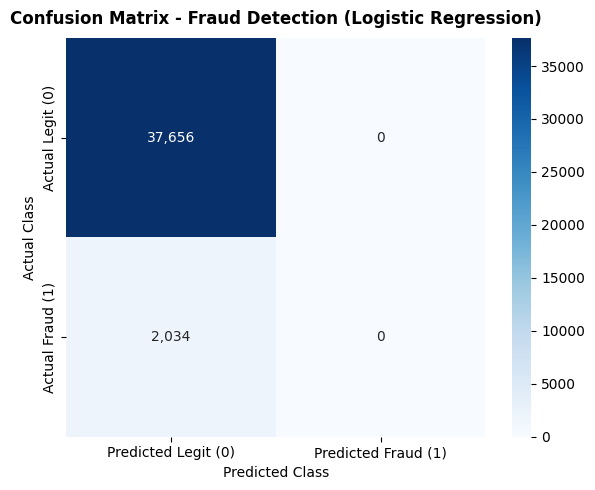

In [9]:
# Set up evaluators for Accuracy and F1-Score
acc_evaluator = MulticlassClassificationEvaluator(labelCol="Is_Fraud", predictionCol="prediction", metricName="accuracy")
f1_evaluator = MulticlassClassificationEvaluator(labelCol="Is_Fraud", predictionCol="prediction", metricName="f1")

models = [
    ("Logistic Regression", preds_lr),
    ("Decision Tree", preds_dt),
    ("Support Vector Machine (SVM)", preds_svm),
    ("Naive Bayes", preds_nb)
]

comparison_records = []

print("="*65)
print(f"{'Classification Model':<30} | {'Accuracy (%)':<15} | {'F1-Score':<10}")
print("="*65)

for model_name, predictions in models:
    accuracy = acc_evaluator.evaluate(predictions) * 100
    f1 = f1_evaluator.evaluate(predictions)
    comparison_records.append({"Model": model_name, "Accuracy (%)": round(accuracy, 2), "F1-Score": round(f1, 4)})
    print(f"{model_name:<30} | {accuracy:<15.2f} | {f1:<10.4f}")

print("="*65)

# Calculate Confusion Matrix for the primary model (Logistic Regression)
cm_data = preds_lr.groupBy("Is_Fraud", "prediction").count().toPandas()

# Build a 2x2 confusion matrix array
confusion_mat = np.zeros((2, 2))
for _, row in cm_data.iterrows():
    actual_label = int(row["Is_Fraud"])
    pred_label = int(row["prediction"])
    confusion_mat[actual_label, pred_label] = row["count"]

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_mat, annot=True, fmt=",.0f", cmap="Blues",
            xticklabels=["Predicted Legit (0)", "Predicted Fraud (1)"],
            yticklabels=["Actual Legit (0)", "Actual Fraud (1)"])
plt.title("Confusion Matrix - Fraud Detection (Logistic Regression)", fontsize=12, fontweight="bold", pad=10)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


### Step 10: Final Results Summary & Clean Shutdown
We compile the results into a concise summary table and stop the SparkSession cleanly.


In [10]:
# Display final comparative summary table
summary_df = pd.DataFrame(comparison_records)
print(">>> Machine Learning Model Performance Summary Table:")
print(summary_df.to_string(index=False))

# Stop SparkSession to free JVM memory and cluster resources
spark.stop()
print("\nSparkSession stopped successfully. All cluster resources released.")


>>> Machine Learning Model Performance Summary Table:
                       Model  Accuracy (%)  F1-Score
         Logistic Regression         94.88    0.9238
               Decision Tree         94.87    0.9238
Support Vector Machine (SVM)         94.88    0.9238
                 Naive Bayes         94.88    0.9238

SparkSession stopped successfully. All cluster resources released.
